# Analysis histograms of the step1 best fit
2D heatmaps of the MC expectation in the analysis binning for the latest best fit
(PassingHESE passing fractions, fixed detector priors, new muon template), with and without the SnowStorm gradient shift.
One figure per variant with cascades, tracks and double cascades next to each other.
Bins with an MC expectation of 0 or below are counted per channel; they are drawn in grey (= 0) and hatched (< 0).

In [4]:
import os, sys
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
import matplotlib.colors as mcolors

from NNMFit.utilities import load_pickle

STEP1_DIR = "/data/user/tvaneede/GlobalFit/reco_processing/NNMFit/notebooks/unblind/step1_hese_flux_reunblind"
sys.path.insert(0, STEP1_DIR)
from plot_configs import _CHAN_SPECS  # analysis binning per channel

graphs_path = f"{STEP1_DIR}/graphs"
plotting_path = f"{STEP1_DIR}/studies/plots_analysis_histograms"
os.makedirs(plotting_path, exist_ok=True)

In [5]:
# latest best fit: PassingHESE passing fractions, fixed detector priors, new muon template
graph_name = "nbestfit50_all_param_2sigma_1D_10steps_PassingHESE_fixedprior_newmuon"
variants = {"syst": "MC_Histogram.pickle", "nosyst": "MC_Histogram_nosyst.pickle"}

In [6]:
def to_2d(flat, spec):
    """Flat analysis histogram -> 2D array (energy, second dimension), same reshape as plot_functions.py;
    the second dimension is flipped where the 1D plots flip it (reco_zenith)."""
    dims = list(spec["binning"])
    h = np.reshape(flat, tuple(len(spec["binning"][d]) - 1 for d in dims))
    if spec["dim_info"][dims[1]]["flip"]:
        h = np.flip(h, axis=1)
    return h

def plot_graph(name, variant):
    hists = load_pickle(f"{graphs_path}/{name}/{variants[variant]}")["histograms"]
    fig, axes = plt.subplots(1, 3, figsize=(18, 5), constrained_layout=True)
    counts = {}
    for ax, (chan_key, chan_label, spec) in zip(axes, _CHAN_SPECS):
        dims = list(spec["binning"])
        xbins, ybins = spec["binning"][dims[0]], spec["binning"][dims[1]]
        h = to_2d(hists[spec["det_config"]], spec)
        n_zero, n_neg = int(np.sum(h == 0)), int(np.sum(h < 0))
        counts[chan_key] = {"bins": h.size, "zero": n_zero, "negative": n_neg, "min": h.min(), "total": h.sum()}

        positive = np.where(h > 0, h, np.nan)
        vmin = np.nanmin(positive) if np.any(h > 0) else 1e-6
        mesh = ax.pcolormesh(xbins, ybins, positive.T, norm=mcolors.LogNorm(vmin=vmin, vmax=np.nanmax(positive)), cmap="viridis")
        # bins with expectation 0 (grey) or below 0 (grey, hatched)
        for mask, hatch in [(h == 0, None), (h < 0, "xx")]:
            if mask.any():
                ax.pcolor(xbins, ybins, np.where(mask, 1.0, np.nan).T, cmap=mcolors.ListedColormap(["lightgrey"]),
                          hatch=hatch, edgecolor="k" if hatch else None, lw=0)
        fig.colorbar(mesh, ax=ax, label="MC expectation")

        ax.set_xscale("log" if spec["dim_info"][dims[0]]["log_x"] else "linear")
        ax.set_xlabel(spec["dim_info"][dims[0]]["x_label"])
        ax.set_ylabel(spec["dim_info"][dims[1]]["x_label"])
        ax.set_title(f"{chan_label}: {h.sum():.2f} events, {n_zero} bins = 0, {n_neg} bins < 0", fontsize=11)
    fig.suptitle(f"{name} ({variant})", fontsize=12)
    fig.savefig(f"{plotting_path}/{name}_{variant}.png", bbox_inches="tight")
    return fig, counts

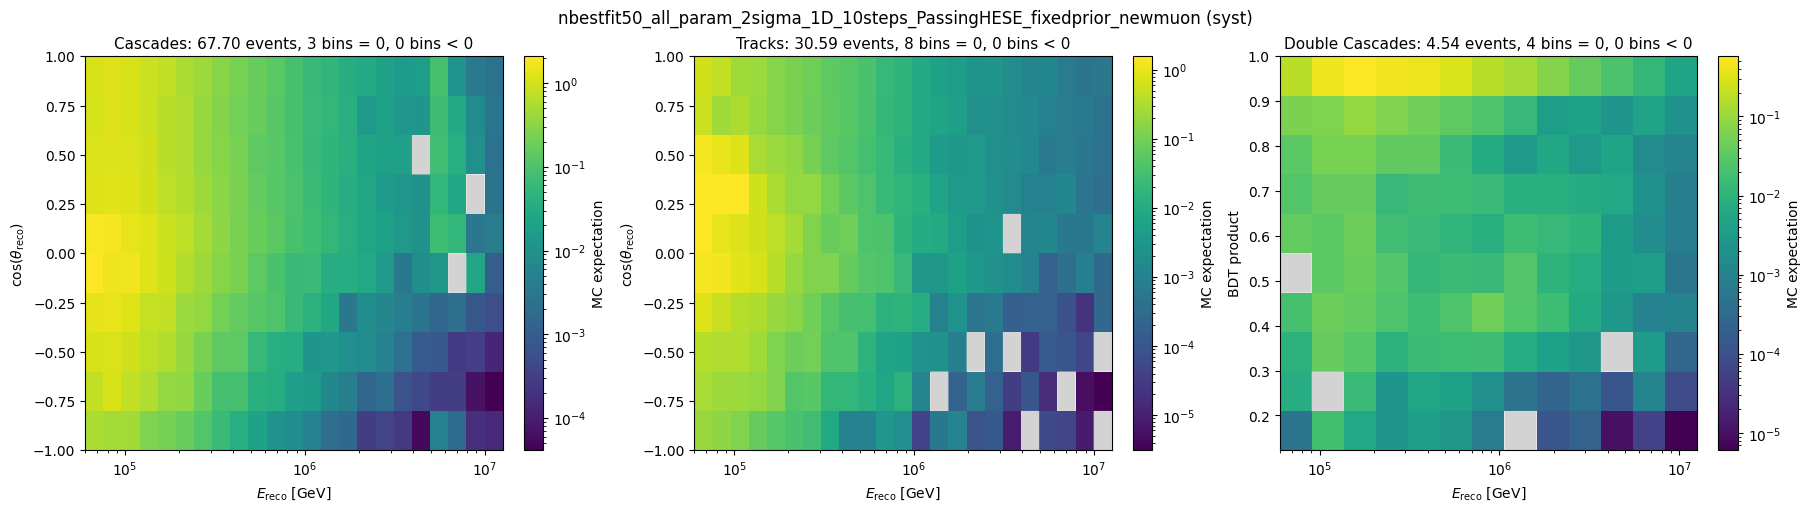

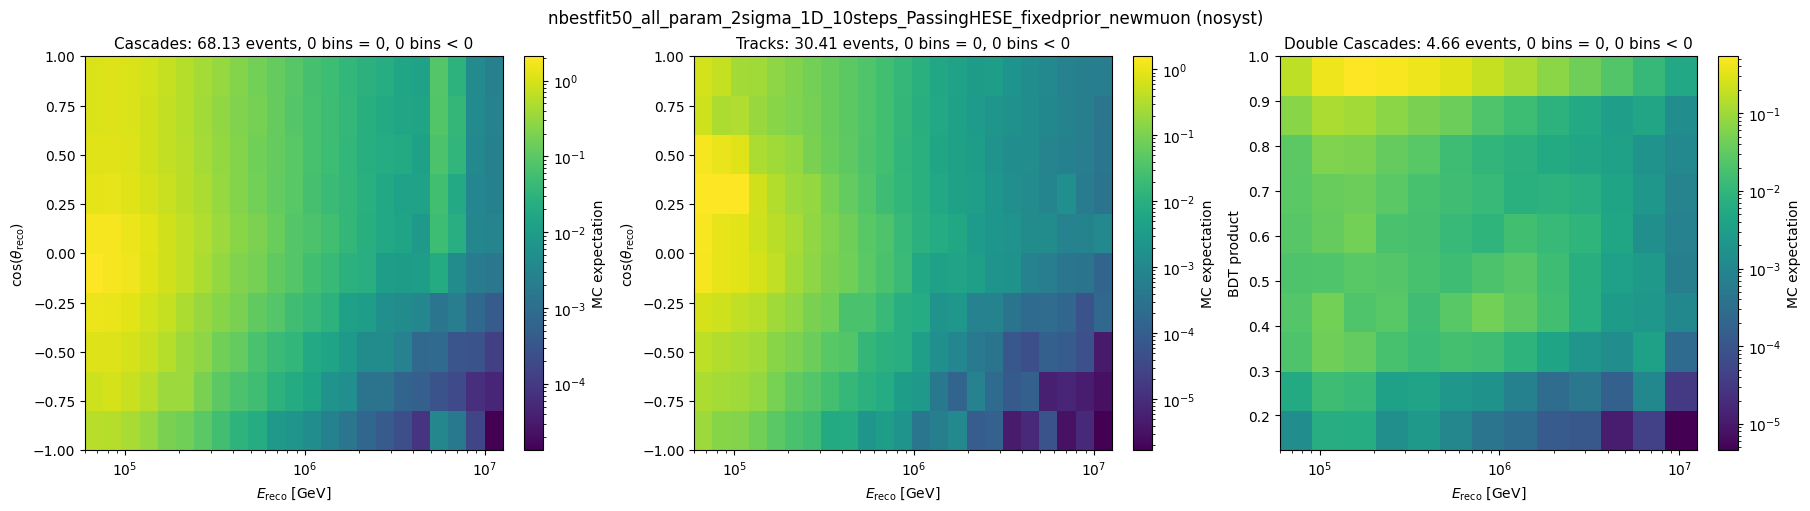

In [7]:
rows = []
for variant in variants:
    fig, counts = plot_graph(graph_name, variant)
    plt.show()
    for chan_key, c in counts.items():
        rows.append({"variant": variant, "channel": chan_key, **c})
df_counts = pd.DataFrame(rows)
df_counts.to_csv(f"{plotting_path}/bin_counts.csv", index=False)

## Bins with MC expectation ≤ 0

In [8]:
with pd.option_context("display.float_format", "{:.3g}".format):
    display(df_counts.set_index(["variant", "channel"]))

bins  zero  negative      min  total
variant channel                                       
syst    cascades   230     3         0        0   67.7
        tracks     230     8         0        0   30.6
        dc         130     4         0        0   4.54
nosyst  cascades   230     0         0 1.33e-05   68.1
        tracks     230     0         0 1.69e-06   30.4
        dc         130     0         0 4.57e-06   4.66